# Parte I

- A instalação de sistemas PV deve ser distribuída por pelo menos 20% das barras do sistema.
- Inicialmente, o total de geração PV deve ser dimensionado para atender à demanda total, considerando as cargas com o valor de pico.
- Fazer as simulações para os seguintes cenários:
  1. Sistema sem geração PV e cargas com valor de pico.
  2. Sistema sem geração PV e cargas com 20% do valor de pico.
  3. Sistema com geração PV e cargas com 20% do valor de pico.
  4. Sistema com geração PV e cargas com valor de pico.
- Em cada cenário, as métricas de sobretensão e sobrecarga nas linhas e transformadores devem ser avaliadas; bem como o nível de fluxo reverso e perdas no sistema.
- Para o cenário 4, caso não haja violação de limites operativos de tensão e carregamento nos elementos, aumente gradativamente a geração PV e verifique em quais níveis de geração PV as violações ocorrem.
- Compare e discuta os resultados obtidos.

# Parte II

- Agregar ao circuito com elevada capacidade de geração instalada um sistema de armazenamento de energia (armazenamento central e armazenamento distribuído), de forma que a energia excedente seja armazenada e os impactos da geração renovável sejam mitigados. Compare os resultados obtidos com as duas abordagens.

# Parte III

- Crie uma Microrrede em parte do circuito e mostre a operação ilhada da rede, avaliando seu tempo de sobrevivência. Simule o ilhamento em diferentes cenários.
- Aplique uma metodologia de corte de carga para aumento de tempo de sobrevivência.

## Simulação 1: PV false, loadmult=1
## Simulação 2: PV false, loadmult=0.2
## Simulação 3: PV true,  loadmult=1
## Simulação 4: PV true, loadmult=0.2
## Simulação 5: PV true, loadmult=1, pmpp=3000, kva=3000
## Simulação 6: PV true, loadmult=1, pmpp=3000, kva=3000
## Simulação 7: PV true, loadmult=1, pmpp=3000, kva=3000
## Simulação 8: PV true, loadmult=1, pmpp=3000, kva=3000
## Simulação 8: PV true, loadmult=1, pmpp=3000, kva=3000

In [3]:
!pip install numpy
!pip install pypiwin32
!pip install pandas
!pip install matplotlib
!pip install dss-python 

In [4]:
import numpy as np    #np, mpl and pd serve as a nicknames
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import os
import dss #OpenDss Module

os.chdir('C:\\Users\\amy\\Desktop\\37Bus\\')   # force going to the working folder (ADJUST FOR YOUR OWN PATH!)
mydir=os.getcwd()                          # mydir stores the working path

dss_engine = dss.DSS
DSSText = dss_engine.Text                                                      
DSSCircuit = dss_engine.ActiveCircuit                                            
DSSSolution = dss_engine.ActiveCircuit.Solution                                      
ControlQueue = dss_engine.ActiveCircuit.CtrlQueue  

In [5]:

def compile():
    DSSText.Command = f'Compile "{mydir}/ieee37.dss"'


In [6]:
def criar_curvas():
    DSSText.Command = 'New XYcurve.PvsT npts=4 xarray=[0 25 75 100] yarray=[1.2 1 .8 .6]'
    DSSText.Command = 'New XYcurve.Effic npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'
    DSSText.Command = 'New loadshape.Irrad npts=24 interval=1 mult=[0 0 0 0 0 0 .1 .2 .3 .5 .8 .9 1.0 1.0 .99 .9 .7 .4 .1 0 0 0 0 0]'
    DSSText.Command = 'New Tshape.Temp npts=24 interval=1 temp=[25 25 25 25 25 25 25 25 35 40 45 50 60 60 55 40 35 30 25 25 25 25 25 25]'
    print('PV curves created')


def pvsystem(nome, phases, bus1, pmpp, kva, kv, conn):
    for n, b in zip(nome, bus1):
        cmd = (f"New PVSystem.{n} phases={phases} bus1={b} kv={kv} conn={conn} "
               f"irrad=1.0 pmpp={pmpp} kva={kva} temperature=25 pf=1 "
               f"%cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT "
               f"Daily=Irrad Tdaily=Temp")
        DSSText.Command = cmd
        print(f"{n} created")

In [7]:
def criar_curvas_storage():
    DSSText.Command = 'New XYcurve.Eff npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'
    DSSText.Command = ('New LoadShape.dispatch_shape npts=24 interval=1 '
                       'mult=[0 0 0 0 0 0 0 0 0 0 -0.3 -0.4 -0.45 -0.45 -0.45 -0.4 -0.15 0.2 0.4 0.6 0.6 0.4 0.2 0]')
    print('Storage curves created')


def storage(nome, phases, bus1, kv, conn, kWrated, kWhrated, stored, reserve):
    for n, b in zip(nome, bus1):
        DSSText.Command = (f"New Storage.{n} phases={phases} bus1={b} kv={kv} conn={conn} "
                           f"kWrated={kWrated} kWhrated={kWhrated} %stored={stored} %reserve={reserve} "
                           f"effcurve=Eff dispmode=follow daily=dispatch_shape pf=1")
        print(f"{n} created")

In [8]:
def ilhamento(linhailha, cargas_ilha, n_corte, nomes_sto, nomes_pv):
    # abre a linha (ex: L27 no terminal 1)
    DSSText.Command = f"Open Line.{linhailha} Term=1"

    # corte de carga, na ordem da lista
    for nome, kw in cargas_ilha[:n_corte]:
        DSSText.Command = f"Edit Load.{nome} enabled=no"

    # controle grid forming
    der = ", ".join([f"Storage.{n}" for n in nomes_sto] +
                    [f"PVSystem.{n}" for n in nomes_pv])
    DSSText.Command = f"New InvControl.StoCtrl DERList=[{der}] mode=GFM"
    for n in nomes_sto:
        DSSText.Command = f"Edit Storage.{n} State=Discharging ControlMode=GFM"

In [9]:
def get_element_names():
    Elenames = DSSCircuit.AllElementNames
    Loadnames = DSSCircuit.Loads.AllNames
    Busnames = DSSCircuit.AllBusNames
    Trafonames = DSSCircuit.Transformers.AllNames
    Linenames = DSSCircuit.Lines.AllNames
    Pvnames = DSSCircuit.PVSystems.AllNames
    Storagenames = DSSCircuit.Storages.AllNames

    print('Elements:', Elenames)
    print('Loads:', Loadnames)
    print('Buses:', Busnames)
    print('Transformers:', Trafonames)
    print('Lines:', Linenames)
    print('PV Systems:', Pvnames)
    print('Storages:', Storagenames)

    return Elenames, Loadnames, Busnames, Trafonames, Linenames, Pvnames, Storagenames

In [10]:
def powerflow(cfg, DSSCircuit, DSSSolution, DSSText):
    Loadnames = cfg["loadnames"]
    Linenames = cfg["linenames"]
    T = cfg["simulation_time"]
    pumin = cfg["pumin"]
    pumax = cfg["pumax"]
    ind_loads = cfg["ind_loads"]

    # ---------- preparar cargas ----------
    DSSCircuit.LoadShapes.New('resd_loadshape')
    DSSCircuit.LoadShapes.Npts = 24
    DSSCircuit.LoadShapes.HrInterval = 1
    DSSCircuit.LoadShapes.Pmult = cfg["resd_profile"]

    DSSCircuit.LoadShapes.New('ind_loadshape')
    DSSCircuit.LoadShapes.Npts = 24
    DSSCircuit.LoadShapes.HrInterval = 1
    DSSCircuit.LoadShapes.Pmult = cfg["ind_profile"]
    print('Loadshapes created')

    for load in Loadnames:
        DSSCircuit.SetActiveElement('load.%s' % load)
        if load.lower() in ind_loads:
            DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
        else:
            DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

    # ---------- limites de tensao e multiplicador de carga ----------
    DSSText.Command = f'set normvminpu={pumin}'
    DSSText.Command = f'set normvmaxpu={pumax}'
    print(f'Voltage limits set to {pumin} p.u. and {pumax} p.u.')

    DSSText.Command = f'set loadmult = {cfg["loadmult"]}'
    print(f'Load multiplier set to {cfg["loadmult"]}')

    # ---------- modo da simulacao ----------
    DSSText.Command = 'reset'
    DSSText.Command = 'set controlmode=static'
    DSSText.Command = 'set mode=daily'
    DSSText.Command = 'set stepsize=1h'
    DSSText.Command = 'set number=1'

    # ---------- nomes ----------
    Pvnames = DSSCircuit.PVSystems.AllNames
    Storagenames = DSSCircuit.Storages.AllNames
    onlytrafo = [n for n in DSSCircuit.Transformers.AllNames if 'reg' not in n.lower()]

    # ---------- onde guardar os resultados ----------
    Total_Act_Power = np.zeros(T)
    Total_React_Power = np.zeros(T)
    Total_Act_Losses = np.zeros(T)
    Total_React_Losses = np.zeros(T)
    busVpuA = [None] * T
    busVpuB = [None] * T
    busVpuC = [None] * T

    Trafo_Max_Amp = np.zeros((len(onlytrafo), T))
    Load_kW = np.zeros((len(Loadnames), T))
    Load_kvar = np.zeros((len(Loadnames), T))
    Line_Max_Amp = np.zeros((len(Linenames), T))
    PV_kW = np.zeros((len(Pvnames), T))
    Storage_kW = np.zeros((len(Storagenames), T))

    def max_current(elem):
        ncond = elem.NumConductors
        return max(elem.CurrentsMagAng[0:2*ncond:2])

    # ---------- loop das horas ----------
    for h in range(T):
        DSSSolution.Solve()

        Total_Act_Power[h] = DSSCircuit.TotalPower[0]
        Total_React_Power[h] = DSSCircuit.TotalPower[1]
        Total_Act_Losses[h] = DSSCircuit.Losses[0] / 1000
        Total_React_Losses[h] = DSSCircuit.Losses[1] / 1000

        busVpuA[h] = DSSCircuit.AllNodeVmagPUByPhase(1)
        busVpuB[h] = DSSCircuit.AllNodeVmagPUByPhase(2)
        busVpuC[h] = DSSCircuit.AllNodeVmagPUByPhase(3)

        for i, t in enumerate(onlytrafo):
            DSSCircuit.SetActiveElement('Transformer.%s' % t)
            Trafo_Max_Amp[i, h] = max_current(DSSCircuit.ActiveElement)

        for i, l in enumerate(Loadnames):
            DSSCircuit.SetActiveElement('Load.%s' % l)
            Load_kW[i, h] = DSSCircuit.ActiveElement.TotalPowers[0]
            Load_kvar[i, h] = DSSCircuit.ActiveElement.TotalPowers[1]

        for i, l in enumerate(Linenames):
            DSSCircuit.SetActiveElement('Line.%s' % l)
            Line_Max_Amp[i, h] = max_current(DSSCircuit.ActiveElement)

        for i, p in enumerate(Pvnames):
            DSSCircuit.SetActiveElement('PVSystem.%s' % p)
            PV_kW[i, h] = DSSCircuit.ActiveElement.TotalPowers[0]

        for i, s in enumerate(Storagenames):
            DSSCircuit.SetActiveElement('Storage.%s' % s)
            Storage_kW[i, h] = DSSCircuit.ActiveElement.TotalPowers[0]

    # ---------- violacoes de tensao (aparece escrito na tela) ----------
    nodesA = DSSCircuit.AllNodeNamesByPhase(1)
    nodesB = DSSCircuit.AllNodeNamesByPhase(2)
    nodesC = DSSCircuit.AllNodeNamesByPhase(3)

    for h in range(T):
        for i in range(len(busVpuA[h])):
            if busVpuA[h][i] < pumin or busVpuA[h][i] > pumax:
                print(f"Hora {h}: violacao de tensao no no {nodesA[i]}: {busVpuA[h][i]} p.u.")
        for i in range(len(busVpuB[h])):
            if busVpuB[h][i] < pumin or busVpuB[h][i] > pumax:
                print(f"Hora {h}: violacao de tensao no no {nodesB[i]}: {busVpuB[h][i]} p.u.")
        for i in range(len(busVpuC[h])):
            if busVpuC[h][i] < pumin or busVpuC[h][i] > pumax:
                print(f"Hora {h}: violacao de tensao no no {nodesC[i]}: {busVpuC[h][i]} p.u.")

    # ---------- sobrecarga nas linhas (aparece escrito na tela) ----------
    for i, l in enumerate(Linenames):
        DSSCircuit.SetActiveElement('Line.%s' % l)
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        for h in range(T):
            if Line_Max_Amp[i, h] > amp_rate:
                print(f"Hora {h}: sobrecarga na linha {l}: {Line_Max_Amp[i, h]:.1f} A (limite {amp_rate} A)")

    return (Total_Act_Power, Total_React_Power, Total_Act_Losses, Total_React_Losses,
            busVpuA, busVpuB, busVpuC, Trafo_Max_Amp, Load_kW, Load_kvar,
            Line_Max_Amp, PV_kW, Storage_kW)

In [11]:
def formatar(titulo, ylabel):
    plt.title(titulo, fontsize=9)
    plt.legend(fontsize=6, loc="upper left")
    plt.yticks(fontsize=8)
    plt.xlabel("hour", fontsize=8)
    plt.ylabel(ylabel, fontsize=8)
    plt.xticks([0, 3, 6, 9, 12, 15, 18, 21, 24], fontsize=8)


def plotar(resultados, cfg, DSSCircuit):
    (Total_Act_Power, Total_React_Power, Total_Act_Losses, Total_React_Losses,
     busVpuA, busVpuB, busVpuC, Trafo_Max_Amp, Load_kW, Load_kvar,
     Line_Max_Amp, PV_kW, Storage_kW) = resultados

    Loadnames = cfg["loadnames"]
    Linenames = cfg["linenames"]
    Pvnames = DSSCircuit.PVSystems.AllNames
    Storagenames = DSSCircuit.Storages.AllNames
    onlytrafo = [n for n in DSSCircuit.Transformers.AllNames if 'reg' not in n.lower()]

    # ---------- total energy ----------
    kWh_SC1 = np.sum(Total_Act_Power)
    kVArh_SC1 = np.sum(Total_React_Power)
    kWh_Loss_SC1 = np.sum(Total_Act_Losses)
    kVArh_Loss_SC1 = np.sum(Total_React_Losses)

    print("Total kWh delivered to the network: %.3f kWh" % kWh_SC1)
    print("Total kVAr delivered to the network: %.3f kvarh" % kVArh_SC1)
    print("Total active losses: %.3f kWh" % kWh_Loss_SC1)
    print("Percent losses: %.3f" % abs((kWh_Loss_SC1 / kWh_SC1) * 100) + "%")
    print("Total reactive losses %.3f kVArh" % kVArh_Loss_SC1)

    # ---------- load power ----------
    dfLoad_kW = pd.DataFrame(Load_kW.T, columns=Loadnames)
    dfLoad_kvar = pd.DataFrame(Load_kvar.T, columns=Loadnames)

    dfLoad_kW.plot(figsize=(6, 3))
    formatar('Load active power', 'kW')

    dfLoad_kvar.plot(figsize=(6, 3))
    formatar('Load reactive power', 'kvar')
    plt.show()

    # ---------- pv power ----------
    if cfg["pv"]:
        plt.figure(figsize=(6, 3))
        for i, nome in enumerate(Pvnames):
            plt.plot(PV_kW[i], label=nome)
        formatar('PV System Outputs', 'kW')
        plt.show()

    # ---------- storage power ----------
    if cfg["storage"]:
        plt.figure(figsize=(6, 3))
        for i, nome in enumerate(Storagenames):
            plt.plot(Storage_kW[i], label=nome)
        formatar('Storage System Outputs', 'kW')
        plt.show()

    # ---------- voltage ----------
    fases = [(1, busVpuA), (2, busVpuB), (3, busVpuC)]
    for fase, bus in fases:
        nodes = DSSCircuit.AllNodeNamesByPhase(fase)
        df = pd.DataFrame(np.vstack(bus), columns=nodes)
        colunas_reg = [col for col in df.columns if col.startswith('reg')]
        df = df.drop(columns=colunas_reg)

        df.plot(figsize=(6, 3))
        formatar('Voltage at all nodes - phase %d' % fase, 'p.u.')
    plt.show()

    # ---------- transformer amps ----------
    Trafo_Loading = np.zeros(Trafo_Max_Amp.shape)
    for i, t in enumerate(onlytrafo):
        DSSCircuit.SetActiveElement('Transformer.%s' % t)
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        Trafo_Loading[i, :] = Trafo_Max_Amp[i, :] / amp_rate

    dfTrafo = pd.DataFrame(Trafo_Loading.T, columns=onlytrafo)
    dfTrafo.plot(figsize=(6, 3))
    formatar('Transformer Maximun Amps Loading', 'p.u.')
    plt.show()

    # ---------- line amps e overloads ----------
    Line_Loading = np.zeros(Line_Max_Amp.shape)
    for i, l in enumerate(Linenames):
        DSSCircuit.SetActiveElement('Line.%s' % l)
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        Line_Loading[i, :] = Line_Max_Amp[i, :] / amp_rate

    dfLine = pd.DataFrame(Line_Loading.T, columns=Linenames)
    dfLine.plot(figsize=(6, 3))
    plt.axhline(1.0, color='r', linestyle='--', linewidth=0.8)  # acima dessa linha vermelha = sobrecarga
    formatar('Line Amps Loading', 'pu')
    plt.show()

    # ---------- substation ----------
    Total_Act_Power_Sub = -Total_Act_Power
    Total_React_Power_Sub = -Total_React_Power
    percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

    plt.figure(figsize=(15, 4))
    plt.suptitle('Power at the substation')

    plt.subplot(1, 3, 1)
    plt.plot(Total_Act_Power_Sub)
    plt.title('Circuit active power', fontsize=9)
    plt.yticks(fontsize=8)
    plt.xlabel("hour", fontsize=8)
    plt.ylabel("kW", fontsize=8)
    plt.xticks([0, 3, 6, 9, 12, 15, 18, 21, 24], fontsize=8)

    plt.subplot(1, 3, 2)
    plt.plot(Total_React_Power_Sub)
    plt.title('Circuit reactive power', fontsize=9)
    plt.yticks(fontsize=8)
    plt.xlabel("hour", fontsize=8)
    plt.ylabel("kvar", fontsize=8)
    plt.xticks([0, 3, 6, 9, 12, 15, 18, 21, 24], fontsize=8)

    plt.subplot(1, 3, 3)
    plt.plot(percentage_losses)
    plt.title('Circuit total active losses', fontsize=9)
    plt.yticks(fontsize=8)
    plt.xlabel("hour", fontsize=8)
    plt.ylabel("%", fontsize=8)
    plt.xticks([0, 3, 6, 9, 12, 15, 18, 21, 24], fontsize=8)

    plt.show()

## Simulação 1: PV false, loadmult=1

Elements: ['Vsource.source', 'Transformer.subxf', 'Transformer.xfm1', 'Line.l1', 'Line.l2', 'Line.l3', 'Line.l4', 'Line.l5', 'Line.l6', 'Line.l7', 'Line.l8', 'Line.l9', 'Line.l10', 'Line.l11', 'Line.l12', 'Line.l13', 'Line.l14', 'Line.l15', 'Line.l16', 'Line.l17', 'Line.l18', 'Line.l19', 'Line.l20', 'Line.l21', 'Line.l22', 'Line.l23', 'Line.l24', 'Line.l25', 'Line.l26', 'Line.l27', 'Line.l28', 'Line.l29', 'Line.l30', 'Line.l31', 'Line.l32', 'Line.l33', 'Line.l34', 'Line.l35', 'Transformer.reg1a', 'RegControl.creg1a', 'Transformer.reg1c', 'RegControl.creg1c', 'Line.jumper', 'Load.s701a', 'Load.s701b', 'Load.s701c', 'Load.s712c', 'Load.s713c', 'Load.s714a', 'Load.s714b', 'Load.s718a', 'Load.s720c', 'Load.s722b', 'Load.s722c', 'Load.s724b', 'Load.s725b', 'Load.s727c', 'Load.s728', 'Load.s729a', 'Load.s730c', 'Load.s731b', 'Load.s732c', 'Load.s733a', 'Load.s734c', 'Load.s735c', 'Load.s736b', 'Load.s737a', 'Load.s738a', 'Load.s740c', 'Load.s741c', 'Load.s742a', 'Load.s742b', 'Load.s744a']
L

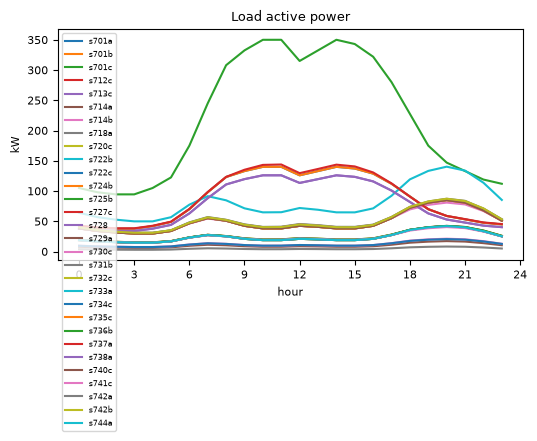

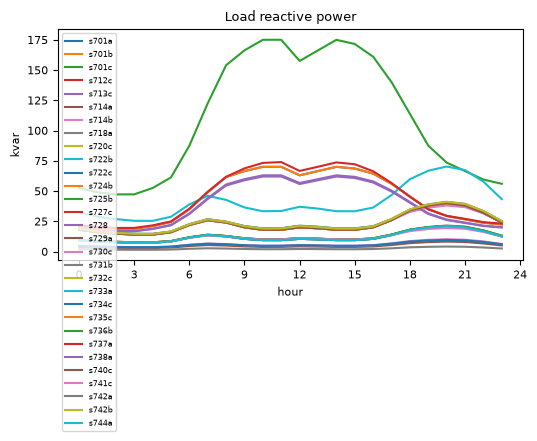

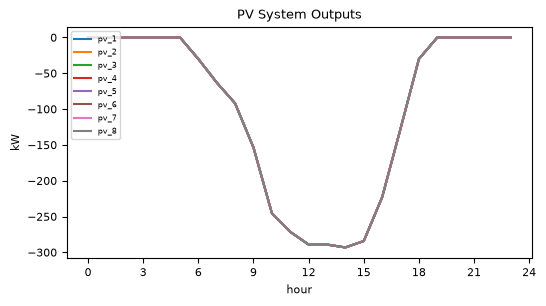

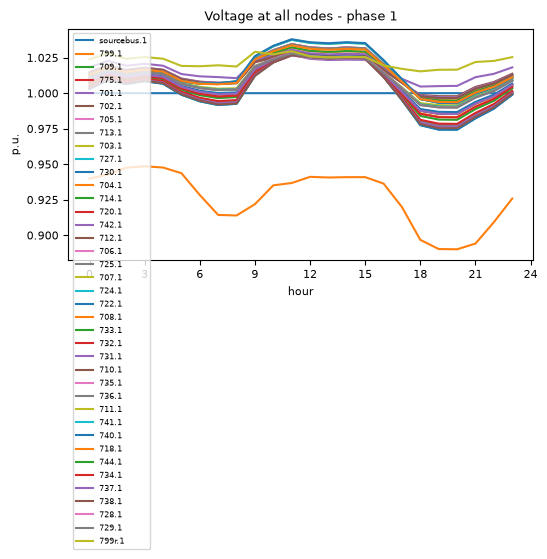

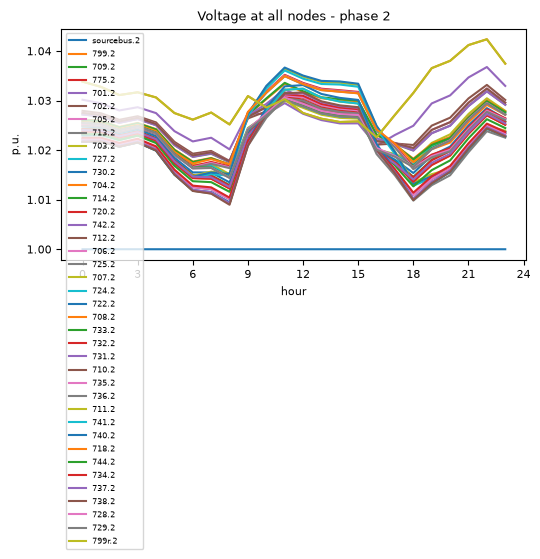

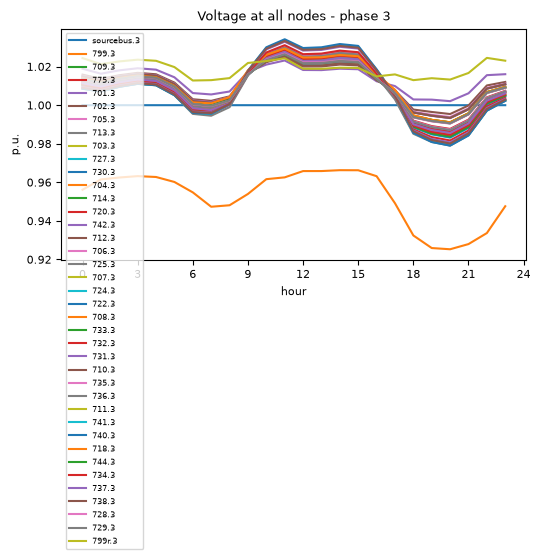

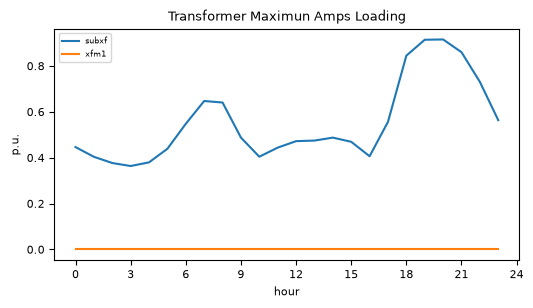

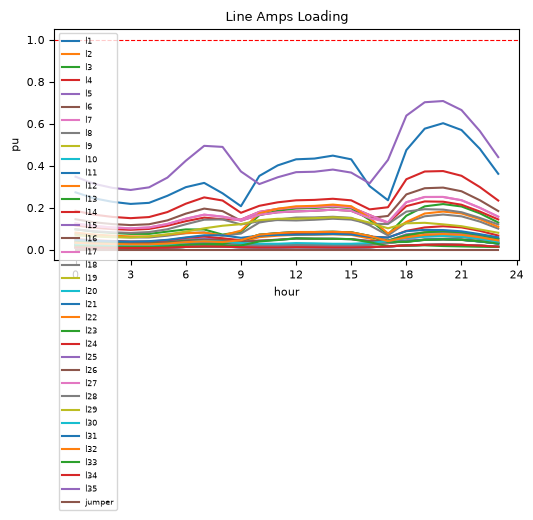

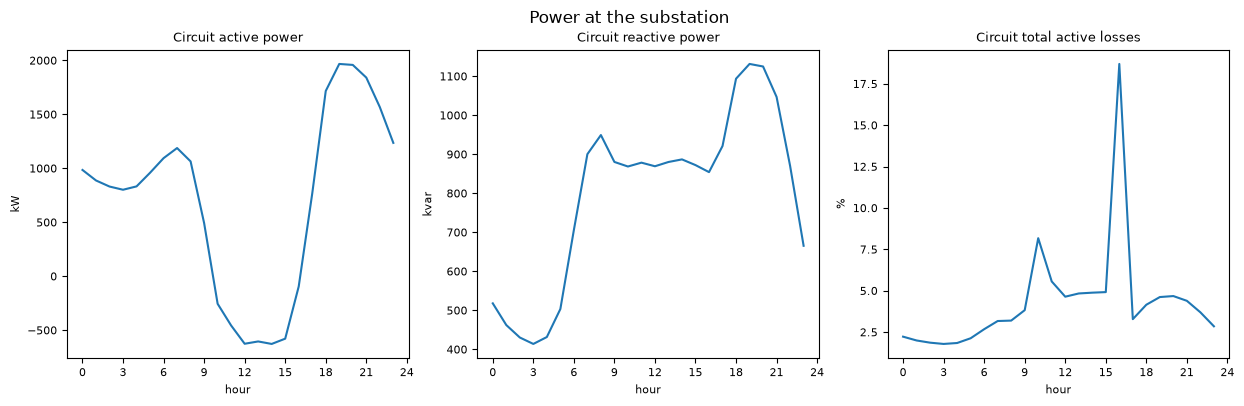

In [12]:
# 1) carrega o circuito (limpa tudo da simulação anterior)
compile()

# 2) pega os nomes, antes do config porque ele usa Loadnames e Linenames
Elenames, Loadnames, Busnames, Trafonames, Linenames, Pvnames, Storagenames = get_element_names()

# 3) config
config = {
    "simulation_time": 24,
    "loadnames": Loadnames,
    "linenames": Linenames,
    "loadmult": 1.0,
    "maxcurrent": 400,

    "resd_profile": [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45, 0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60],
    "ind_profile": [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00, 0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32],
    "ind_loads": ['s701a', 's701b', 's701c', 's728', 's737a', 's738a'],

    "pumin": 0.93,
    "pumax": 1.05,

    "pv": True,
    "pv_params": {
        "nome": ["pv_1", "pv_2", "pv_3", "pv_4", "pv_5", "pv_6", "pv_7", "pv_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "pmpp": 350,
        "kva": 350,
        "kv": 4.8,
        "conn": "delta",
    },

    "storage": False,
    "storage_params": {
        "nome": ["sto_1", "sto_2", "sto_3", "sto_4", "sto_5", "sto_6", "sto_7", "sto_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "kv": 4.8,
        "conn": "delta",
        "kWrated": 50,
        "kWhrated": 5000,
        "stored": 30,
        "reserve": 20,
    },

    "ilhamento": False,
    "linhailha": "L27",
    "n_corte": 0,
    "cargas_ilha": [("S736b", 42), ("S741c", 42), ("S732c", 42), ("S734c", 42),
                    ("S735c", 85), ("S733a", 85), ("S740c", 85),
                    ("S738a", 126), ("S737a", 140)],
}

# 4) cria PV, storage e ilhamento (só o que estiver True)
if config["pv"]:
    criar_curvas()
    pvsystem(**config["pv_params"])

if config["storage"]:
    criar_curvas_storage()
    storage(**config["storage_params"])

if config["ilhamento"]:
    ilhamento(config["linhailha"], config["cargas_ilha"], config["n_corte"],
              config["storage_params"]["nome"], config["pv_params"]["nome"])

# 5) fluxo de potência (guarda os resultados)
resultados = powerflow(config, DSSCircuit, DSSSolution, DSSText)

# 6) gráficos
plotar(resultados, config, DSSCircuit)

Elements: ['Vsource.source', 'Transformer.subxf', 'Transformer.xfm1', 'Line.l1', 'Line.l2', 'Line.l3', 'Line.l4', 'Line.l5', 'Line.l6', 'Line.l7', 'Line.l8', 'Line.l9', 'Line.l10', 'Line.l11', 'Line.l12', 'Line.l13', 'Line.l14', 'Line.l15', 'Line.l16', 'Line.l17', 'Line.l18', 'Line.l19', 'Line.l20', 'Line.l21', 'Line.l22', 'Line.l23', 'Line.l24', 'Line.l25', 'Line.l26', 'Line.l27', 'Line.l28', 'Line.l29', 'Line.l30', 'Line.l31', 'Line.l32', 'Line.l33', 'Line.l34', 'Line.l35', 'Transformer.reg1a', 'RegControl.creg1a', 'Transformer.reg1c', 'RegControl.creg1c', 'Line.jumper', 'Load.s701a', 'Load.s701b', 'Load.s701c', 'Load.s712c', 'Load.s713c', 'Load.s714a', 'Load.s714b', 'Load.s718a', 'Load.s720c', 'Load.s722b', 'Load.s722c', 'Load.s724b', 'Load.s725b', 'Load.s727c', 'Load.s728', 'Load.s729a', 'Load.s730c', 'Load.s731b', 'Load.s732c', 'Load.s733a', 'Load.s734c', 'Load.s735c', 'Load.s736b', 'Load.s737a', 'Load.s738a', 'Load.s740c', 'Load.s741c', 'Load.s742a', 'Load.s742b', 'Load.s744a']
L

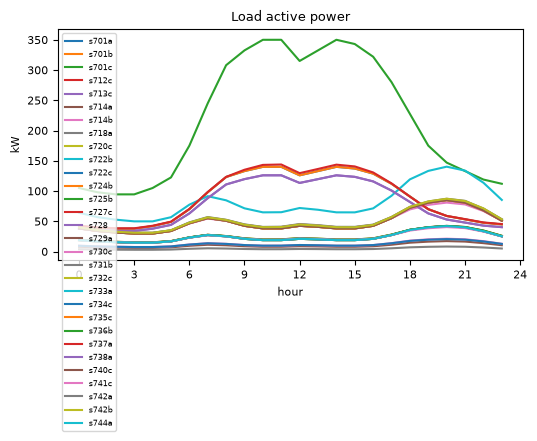

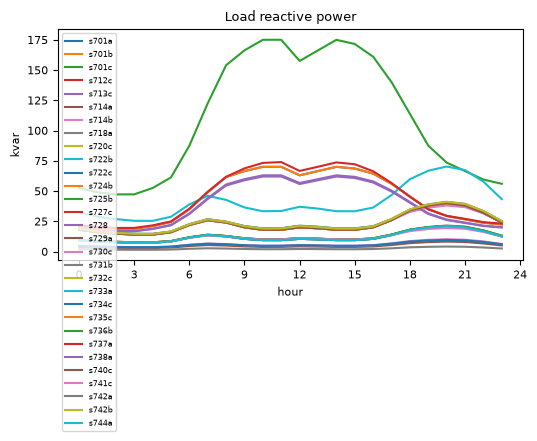

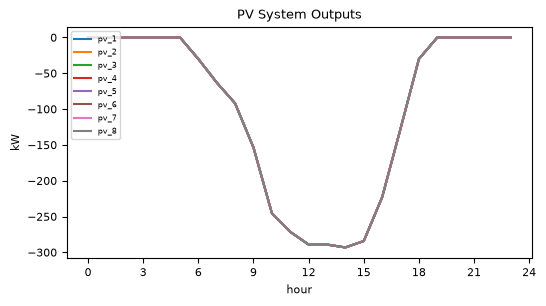

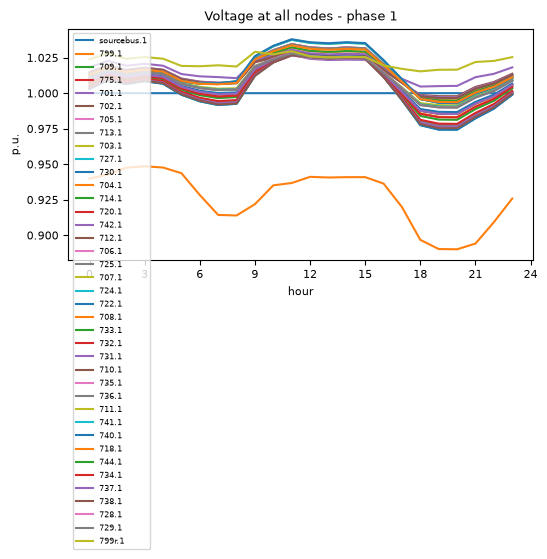

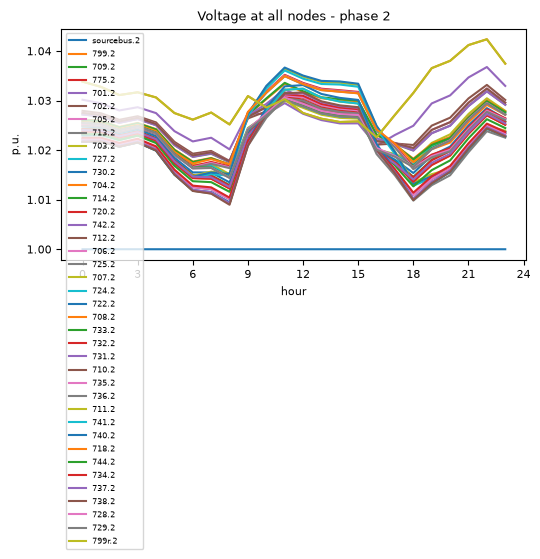

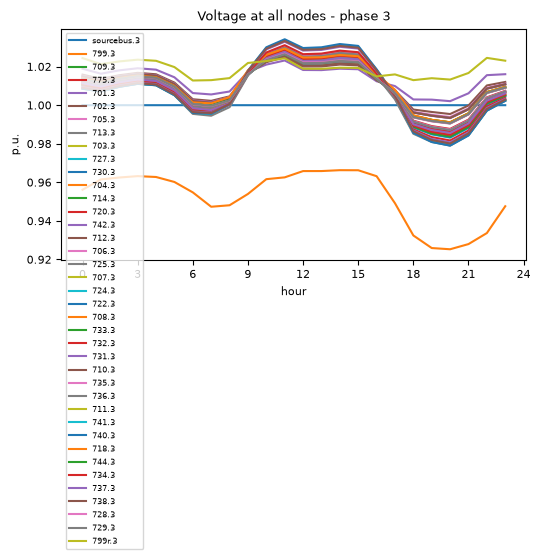

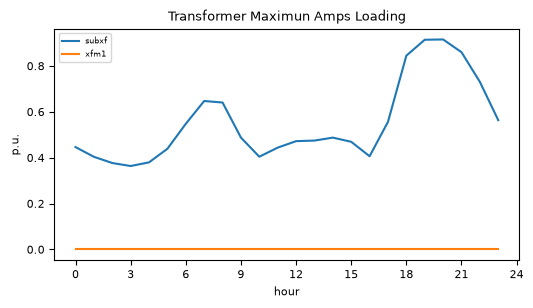

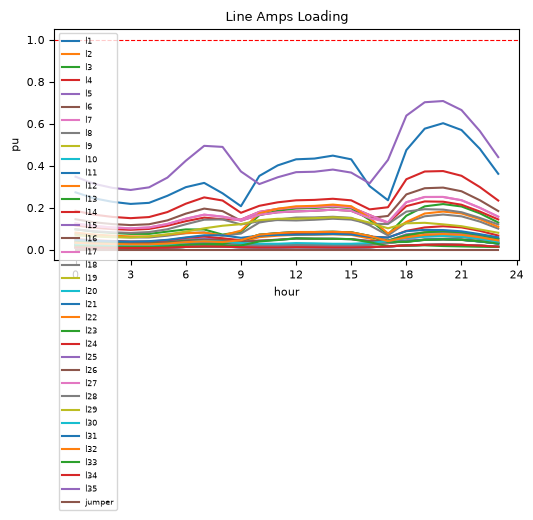

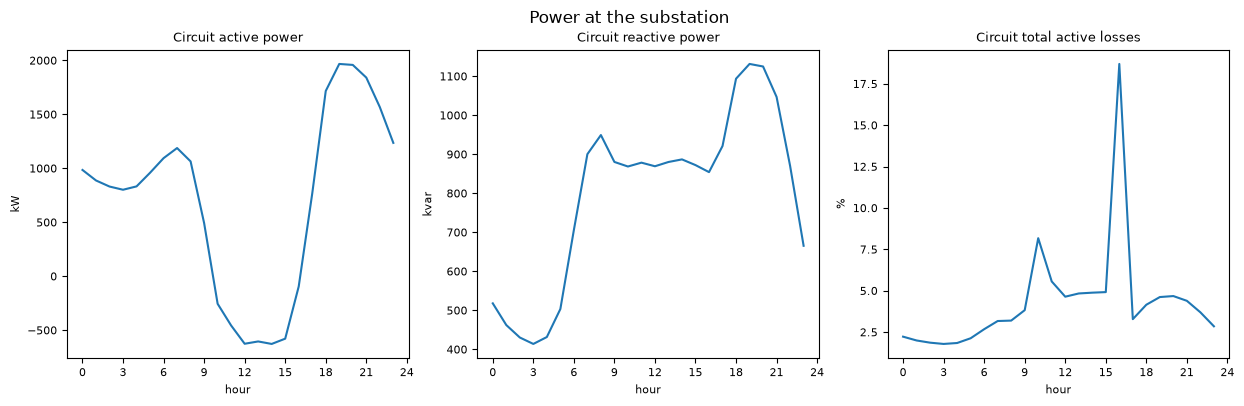

In [13]:
# 1) carrega o circuito (limpa tudo da simulação anterior)
compile()

# 2) pega os nomes, antes do config porque ele usa Loadnames e Linenames
Elenames, Loadnames, Busnames, Trafonames, Linenames, Pvnames, Storagenames = get_element_names()

# 3) config
config = {
    "simulation_time": 24,
    "loadnames": Loadnames,
    "linenames": Linenames,
    "loadmult": 1.0,
    "maxcurrent": 400,

    "resd_profile": [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45, 0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60],
    "ind_profile": [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00, 0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32],
    "ind_loads": ['s701a', 's701b', 's701c', 's728', 's737a', 's738a'],

    "pumin": 0.93,
    "pumax": 1.05,

    "pv": True,
    "pv_params": {
        "nome": ["pv_1", "pv_2", "pv_3", "pv_4", "pv_5", "pv_6", "pv_7", "pv_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "pmpp": 350,
        "kva": 350,
        "kv": 4.8,
        "conn": "delta",
    },

    "storage": False,
    "storage_params": {
        "nome": ["sto_1", "sto_2", "sto_3", "sto_4", "sto_5", "sto_6", "sto_7", "sto_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "kv": 4.8,
        "conn": "delta",
        "kWrated": 50,
        "kWhrated": 5000,
        "stored": 30,
        "reserve": 20,
    },

    "ilhamento": False,
    "linhailha": "L27",
    "n_corte": 0,
    "cargas_ilha": [("S736b", 42), ("S741c", 42), ("S732c", 42), ("S734c", 42),
                    ("S735c", 85), ("S733a", 85), ("S740c", 85),
                    ("S738a", 126), ("S737a", 140)],
}

# 4) cria PV, storage e ilhamento (só o que estiver True)
if config["pv"]:
    criar_curvas()
    pvsystem(**config["pv_params"])

if config["storage"]:
    criar_curvas_storage()
    storage(**config["storage_params"])

if config["ilhamento"]:
    ilhamento(config["linhailha"], config["cargas_ilha"], config["n_corte"],
              config["storage_params"]["nome"], config["pv_params"]["nome"])

# 5) fluxo de potência (guarda os resultados)
resultados = powerflow(config, DSSCircuit, DSSSolution, DSSText)

# 6) gráficos
plotar(resultados, config, DSSCircuit)

## Simulação 2: PV false, loadmult=0.2

In [17]:
config = {
    # Parâmetros gerais da simulação
    "simulation_time": 24,
    "loadnames": Loadnames,
    "linenames": Linenames,
    "loadmult": 1.0,
    "maxcurrent": 400,

    # Perfis de carga (24h)
    "resd_profile": [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45, 0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60,
    ],
    "ind_profile": [ 0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00, 0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32,
    ],

    # Cargas industriais
    "ind_loads": ['s701a', 's701b', 's701c', 's728', 's737a', 's738a'],

    # Limites de potência
    "pumin": 0.93,
    "pumax": 1.05,

  
    "pv": True,
    "pv_params": {
        "nome": ["pv_1", "pv_2", "pv_3", "pv_4", "pv_5", "pv_6", "pv_7", "pv_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "pmpp": 350,
        "kva": 350,
        "kv": 4.8,
        "conn": "delta",
    },

    "storage": True,
    "storage_params": {
        "nome": ["sto_1", "sto_2", "sto_3", "sto_4", "sto_5", "sto_6", "sto_7", "sto_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "kv": 4.8,
        "conn": "delta",
        "kWrated": 50,
        "kWhrated": 5000,
        "stored": 30,
        "reserve": 20,
    },
    # Ilhamento
    "ilhamento": False,
    "linhailha":[], 
}

## Simulação 3: PV true,  loadmult=1


In [ ]:
config = {
    # Parâmetros gerais da simulação
    "simulation_time": 24,
    "loadnames": Loadnames,
    "linenames": Linenames,
    "loadmult": 1.0,
    "maxcurrent": 400,

    # Perfis de carga (24h)
    "resd_profile": [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45, 0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60,
    ],
    "ind_profile": [ 0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00, 0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32,
    ],

    # Cargas industriais
    "ind_loads": ['s701a', 's701b', 's701c', 's728', 's737a', 's738a'],

    # Limites de potência
    "pumin": 0.93,
    "pumax": 1.05,

  
    "pv": True,
    "pv_params": {
        "nome": ["pv_1", "pv_2", "pv_3", "pv_4", "pv_5", "pv_6", "pv_7", "pv_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "pmpp": 350,
        "kva": 350,
        "kv": 4.8,
        "conn": "delta",
    },

    "storage": True,
    "storage_params": {
        "nome": ["sto_1", "sto_2", "sto_3", "sto_4", "sto_5", "sto_6", "sto_7", "sto_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "kv": 4.8,
        "conn": "delta",
        "kWrated": 50,
        "kWhrated": 5000,
        "stored": 30,
        "reserve": 20,
    },
    # Ilhamento
    "ilhamento": False,
    "linhailha": linhailha,
}

## Simulação 4: PV true, loadmult=0.2


In [ ]:
config = {
    # Parâmetros gerais da simulação
    "simulation_time": 24,
    "loadnames": Loadnames,
    "linenames": Linenames,
    "loadmult": 1.0,
    "maxcurrent": 400,

    # Perfis de carga (24h)
    "resd_profile": [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45, 0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60,
    ],
    "ind_profile": [ 0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00, 0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32,
    ],

    # Cargas industriais
    "ind_loads": ['s701a', 's701b', 's701c', 's728', 's737a', 's738a'],

    # Limites de potência
    "pumin": 0.93,
    "pumax": 1.05,

  
    "pv": True,
    "pv_params": {
        "nome": ["pv_1", "pv_2", "pv_3", "pv_4", "pv_5", "pv_6", "pv_7", "pv_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "pmpp": 350,
        "kva": 350,
        "kv": 4.8,
        "conn": "delta",
    },

    "storage": True,
    "storage_params": {
        "nome": ["sto_1", "sto_2", "sto_3", "sto_4", "sto_5", "sto_6", "sto_7", "sto_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "kv": 4.8,
        "conn": "delta",
        "kWrated": 50,
        "kWhrated": 5000,
        "stored": 30,
        "reserve": 20,
    },
    # Ilhamento
    "ilhamento": False,
    "linhailha": linhailha,
}

## Simulação 5: PV true, loadmult=1, pmpp=3000, kva=3000


In [ ]:
config = {
    # Parâmetros gerais da simulação
    "simulation_time": 24,
    "loadnames": Loadnames,
    "linenames": Linenames,
    "loadmult": 1.0,
    "maxcurrent": 400,

    # Perfis de carga (24h)
    "resd_profile": [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45, 0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60,
    ],
    "ind_profile": [ 0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00, 0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32,
    ],

    # Cargas industriais
    "ind_loads": ['s701a', 's701b', 's701c', 's728', 's737a', 's738a'],

    # Limites de potência
    "pumin": 0.93,
    "pumax": 1.05,

  
    "pv": True,
    "pv_params": {
        "nome": ["pv_1", "pv_2", "pv_3", "pv_4", "pv_5", "pv_6", "pv_7", "pv_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "pmpp": 350,
        "kva": 350,
        "kv": 4.8,
        "conn": "delta",
    },

    "storage": True,
    "storage_params": {
        "nome": ["sto_1", "sto_2", "sto_3", "sto_4", "sto_5", "sto_6", "sto_7", "sto_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "kv": 4.8,
        "conn": "delta",
        "kWrated": 50,
        "kWhrated": 5000,
        "stored": 30,
        "reserve": 20,
    },
    # Ilhamento
    "ilhamento": False,
    "linhailha": linhailha,
}

## Simulação 6: PV true, loadmult=1, pmpp=3000, kva=3000


In [ ]:
config = {
    # Parâmetros gerais da simulação
    "simulation_time": 24,
    "loadnames": Loadnames,
    "linenames": Linenames,
    "loadmult": 1.0,
    "maxcurrent": 400,

    # Perfis de carga (24h)
    "resd_profile": [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45, 0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60,
    ],
    "ind_profile": [ 0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00, 0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32,
    ],

    # Cargas industriais
    "ind_loads": ['s701a', 's701b', 's701c', 's728', 's737a', 's738a'],

    # Limites de potência
    "pumin": 0.93,
    "pumax": 1.05,

  
    "pv": True,
    "pv_params": {
        "nome": ["pv_1", "pv_2", "pv_3", "pv_4", "pv_5", "pv_6", "pv_7", "pv_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "pmpp": 350,
        "kva": 350,
        "kv": 4.8,
        "conn": "delta",
    },

    "storage": True,
    "storage_params": {
        "nome": ["sto_1", "sto_2", "sto_3", "sto_4", "sto_5", "sto_6", "sto_7", "sto_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "kv": 4.8,
        "conn": "delta",
        "kWrated": 50,
        "kWhrated": 5000,
        "stored": 30,
        "reserve": 20,
    },
    # Ilhamento
    "ilhamento": False,
    "linhailha": linhailha,
}

## Simulação 7: PV true, loadmult=1, pmpp=3000, kva=3000


In [ ]:
config = {
    # Parâmetros gerais da simulação
    "simulation_time": 24,
    "loadnames": Loadnames,
    "linenames": Linenames,
    "loadmult": 1.0,
    "maxcurrent": 400,

    # Perfis de carga (24h)
    "resd_profile": [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45, 0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60,
    ],
    "ind_profile": [ 0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00, 0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32,
    ],

    # Cargas industriais
    "ind_loads": ['s701a', 's701b', 's701c', 's728', 's737a', 's738a'],

    # Limites de potência
    "pumin": 0.93,
    "pumax": 1.05,

  
    "pv": True,
    "pv_params": {
        "nome": ["pv_1", "pv_2", "pv_3", "pv_4", "pv_5", "pv_6", "pv_7", "pv_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "pmpp": 350,
        "kva": 350,
        "kv": 4.8,
        "conn": "delta",
    },

    "storage": True,
    "storage_params": {
        "nome": ["sto_1", "sto_2", "sto_3", "sto_4", "sto_5", "sto_6", "sto_7", "sto_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "kv": 4.8,
        "conn": "delta",
        "kWrated": 50,
        "kWhrated": 5000,
        "stored": 30,
        "reserve": 20,
    },
    # Ilhamento
    "ilhamento": False,
    "linhailha": linhailha,
}

## Simulação 8: PV true, loadmult=1, pmpp=3000, kva=3000


In [ ]:
config = {
    # Parâmetros gerais da simulação
    "simulation_time": 24,
    "loadnames": Loadnames,
    "linenames": Linenames,
    "loadmult": 1.0,
    "maxcurrent": 400,

    # Perfis de carga (24h)
    "resd_profile": [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45, 0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60,
    ],
    "ind_profile": [ 0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00, 0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32,
    ],

    # Cargas industriais
    "ind_loads": ['s701a', 's701b', 's701c', 's728', 's737a', 's738a'],

    # Limites de potência
    "pumin": 0.93,
    "pumax": 1.05,

  
    "pv": True,
    "pv_params": {
        "nome": ["pv_1", "pv_2", "pv_3", "pv_4", "pv_5", "pv_6", "pv_7", "pv_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "pmpp": 350,
        "kva": 350,
        "kv": 4.8,
        "conn": "delta",
    },

    "storage": True,
    "storage_params": {
        "nome": ["sto_1", "sto_2", "sto_3", "sto_4", "sto_5", "sto_6", "sto_7", "sto_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "kv": 4.8,
        "conn": "delta",
        "kWrated": 50,
        "kWhrated": 5000,
        "stored": 30,
        "reserve": 20,
    },
    "ilhamento": False,
    "linhailha": "L27",
    "n_corte": 0,   # quantas cargas cortar, na ordem da lista (0 = sem corte)
    "cargas_ilha": [("S736b", 42), ("S741c", 42), ("S732c", 42), ("S734c", 42),
                    ("S735c", 85), ("S733a", 85), ("S740c", 85),
                    ("S738a", 126), ("S737a", 140)],

} 

## Simulação 8: PV true, loadmult=1, pmpp=3000, kva=3000

In [ ]:
config = {
    # Parâmetros gerais da simulação
    "simulation_time": 24,
    "loadnames": Loadnames,
    "linenames": Linenames,
    "loadmult": 1.0,
    "maxcurrent": 400,

    # Perfis de carga (24h)
    "resd_profile": [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45, 0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60,
    ],
    "ind_profile": [ 0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00, 0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32,
    ],

    # Cargas industriais
    "ind_loads": ['s701a', 's701b', 's701c', 's728', 's737a', 's738a'],

    # Limites de potência
    "pumin": 0.93,
    "pumax": 1.05,

  
    "pv": True,
    "pv_params": {
        "nome": ["pv_1", "pv_2", "pv_3", "pv_4", "pv_5", "pv_6", "pv_7", "pv_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "pmpp": 350,
        "kva": 350,
        "kv": 4.8,
        "conn": "delta",
    },

    "storage": True,
    "storage_params": {
        "nome": ["sto_1", "sto_2", "sto_3", "sto_4", "sto_5", "sto_6", "sto_7", "sto_8"],
        "phases": 3,
        "bus1": ["728.1.2.3", "733.1.2.3", "737.1.2.3", "740.1.2.3",
                 "718.1.2.3", "720.1.2.3", "722.1.2.3", "742.1.2.3"],
        "kv": 4.8,
        "conn": "delta",
        "kWrated": 50,
        "kWhrated": 5000,
        "stored": 30,
        "reserve": 20,
    },
    "ilhamento": False,
    "linhailha": "L27",
    "n_corte": 0,   # quantas cargas cortar, na ordem da lista (0 = sem corte)
    "cargas_ilha": [("S736b", 42), ("S741c", 42), ("S732c", 42), ("S734c", 42),
                    ("S735c", 85), ("S733a", 85), ("S740c", 85),
                    ("S738a", 126), ("S737a", 140)],

}                    